# 01 · Análisis Exploratorio de Datos (EDA)

**Fase 2 de CRISP-DM — Comprensión de los datos.**

Objetivo: conocer a fondo el dataset base *Fruit Quality Classification* (Kaggle) antes de preparar
los datos y modelar. Analizamos:
1. Inventario y distribución de clases (calidad y por fruta) → **desbalanceo**.
2. Propiedades de las imágenes (formato, dimensiones, relación de aspecto).
3. Muestras visuales por fruta y calidad.
4. Análisis de color/brillo por clase (¿hay señal separable?).
5. La carpeta `Mixed Quality` (sin etiqueta de calidad → material para la clase `Defectuosa`).

> Este notebook se genera desde `notebooks/01_eda.py` (jupytext) y se ejecuta con nbconvert.
> Las figuras se guardan en `assets/eda/` para el informe.

In [1]:
from pathlib import Path
from collections import Counter
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Rutas robustas (el notebook puede ejecutarse desde notebooks/ o desde la raíz)
ROOT = Path.cwd()
if (ROOT / "notebooks").exists() is False and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"
ASSETS = ROOT / "assets" / "eda"
ASSETS.mkdir(parents=True, exist_ok=True)
IMG_EXTS = {".jpg", ".jpeg", ".png"}
print("RAW_DIR:", RAW_DIR)

RAW_DIR: /Users/srengifo/Desktop/APO3 FP/fruit-quality-classification/data/raw


## 1. Inventario del dataset

Recorremos la estructura de carpetas y contamos imágenes por grupo de calidad y por fruta.

In [2]:
def list_images(folder: Path):
    return [f for f in folder.rglob("*") if f.suffix.lower() in IMG_EXTS]

rows = []
for group in sorted(RAW_DIR.iterdir()):
    if not group.is_dir():
        continue
    for sub in sorted(group.iterdir()):
        if sub.is_dir():
            rows.append({
                "grupo": group.name,
                "carpeta": sub.name,
                "n": len(list_images(sub)),
            })
inv = pd.DataFrame(rows)
total = inv["n"].sum()
print(f"Total de imágenes: {total}")
inv

Total de imágenes: 19526


,grupo,carpeta,n
0,Bad Quality_Fruits,Apple_Bad,1141
1,Bad Quality_Fruits,Banana_Bad,1087
2,Bad Quality_Fruits,Guava_Bad,1129
3,Bad Quality_Fruits,Lime_Bad,1085
4,Bad Quality_Fruits,Orange_Bad,1159
5,Bad Quality_Fruits,Pomegranate_Bad,1187
6,Good Quality_Fruits,Apple_Good,1149
7,Good Quality_Fruits,Banana_Good,1113
8,Good Quality_Fruits,Guava_Good,1152
9,Good Quality_Fruits,Lime_Good,1094


## 2. Distribución por nivel de calidad

El dataset base trae **dos niveles etiquetados** (`Good`, `Bad`) más `Mixed Quality` (sin etiqueta).

grupo
Good Quality_Fruits    11664
Bad Quality_Fruits      6788
Mixed Qualit_Fruits     1074
Name: n, dtype: int64

Proporción:
grupo
Good Quality_Fruits    59.7 %
Bad Quality_Fruits     34.8 %
Mixed Qualit_Fruits     5.5 %
Name: n, dtype: str


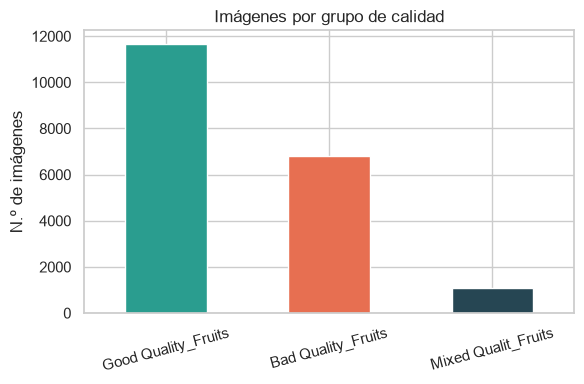

In [3]:
by_group = inv.groupby("grupo")["n"].sum().sort_values(ascending=False)
print(by_group)
print("\nProporción:")
print((by_group / total * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(6, 4))
by_group.plot(kind="bar", color=["#2a9d8f", "#e76f51", "#264653"], ax=ax)
ax.set_title("Imágenes por grupo de calidad")
ax.set_ylabel("N.º de imágenes")
ax.set_xlabel("")
plt.xticks(rotation=15)
plt.tight_layout()
fig.savefig(ASSETS / "dist_calidad.svg")
fig.savefig(ASSETS / "dist_calidad.png", dpi=120)
plt.show()

## 3. Distribución por fruta y calidad (detección de desbalanceo)

Separamos fruta y calidad para ver si alguna clase domina.

calidad       Bad  Good
fruta                  
Apple        1141  1149
Banana       1087  1113
Guava        1129  1152
Lime         1085  1094
Orange       1159  1216
Pomegranate  1187  5940


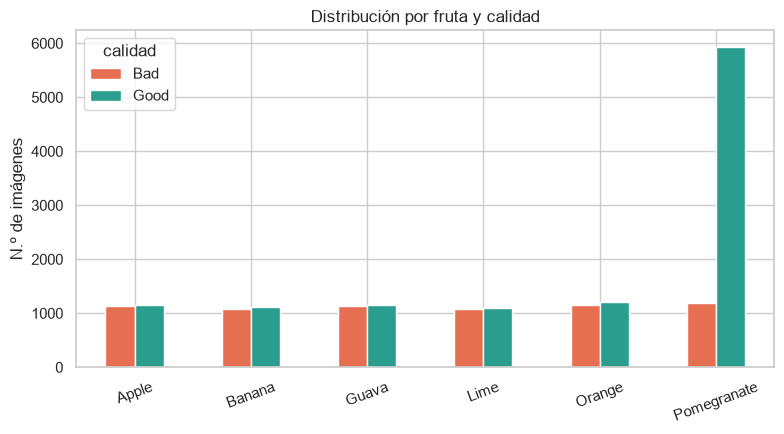


Clase mayor: Pomegranate_Good = 5940
Clase menor: Lime_Bad = 1085
Ratio de desbalanceo (mayor/menor): 5.5x


In [4]:
etiquetadas = inv[inv["grupo"] != "Mixed Qualit_Fruits"].copy()
etiquetadas["fruta"] = etiquetadas["carpeta"].str.replace("_Good", "").str.replace("_Bad", "")
etiquetadas["calidad"] = np.where(etiquetadas["carpeta"].str.contains("Good"), "Good", "Bad")

pivot = etiquetadas.pivot_table(index="fruta", columns="calidad", values="n", aggfunc="sum", fill_value=0)
print(pivot)

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot.plot(kind="bar", ax=ax, color={"Good": "#2a9d8f", "Bad": "#e76f51"})
ax.set_title("Distribución por fruta y calidad")
ax.set_ylabel("N.º de imágenes")
ax.set_xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(ASSETS / "dist_fruta_calidad.svg")
fig.savefig(ASSETS / "dist_fruta_calidad.png", dpi=120)
plt.show()

# Ratio de desbalanceo
mx, mn = etiquetadas["n"].max(), etiquetadas["n"].min()
print(f"\nClase mayor: {etiquetadas.loc[etiquetadas['n'].idxmax(), 'carpeta']} = {mx}")
print(f"Clase menor: {etiquetadas.loc[etiquetadas['n'].idxmin(), 'carpeta']} = {mn}")
print(f"Ratio de desbalanceo (mayor/menor): {mx/mn:.1f}x")

## 4. Propiedades de las imágenes (formato y dimensiones)

Muestreamos imágenes para caracterizar formato, resolución y relación de aspecto.
Es clave para decidir el **redimensionado** en la fase de preparación.

Extensiones: Counter({'.jpg': 19526})



Muestra: 500 imágenes
Ancho  → min=192, mediana=256, max=8000
Alto   → min=192, mediana=256, max=6000
Aspecto (w/h) → min=0.75, mediana=1.00, max=1.33

Dimensiones más frecuentes:
   (np.int64(256), np.int64(256)): 315
   (np.int64(192), np.int64(256)): 118
   (np.int64(256), np.int64(192)): 51
   (np.int64(3000), np.int64(4000)): 12
   (np.int64(8000), np.int64(6000)): 4


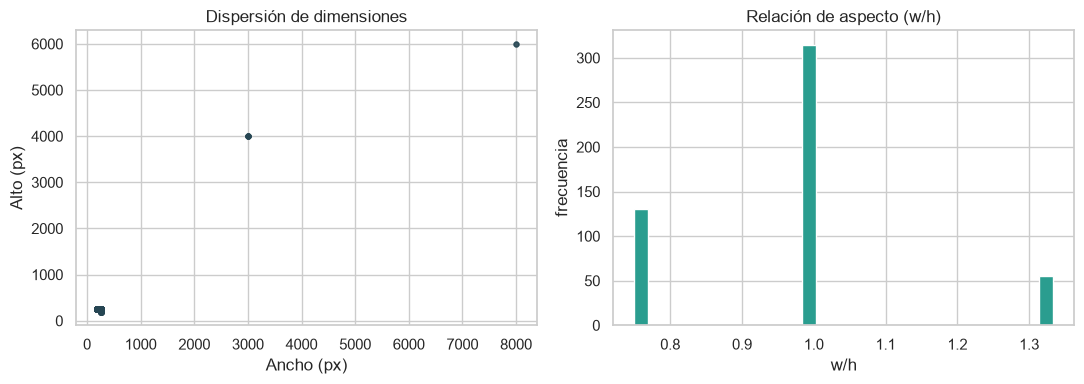

In [5]:
all_imgs = list_images(RAW_DIR)
print("Extensiones:", Counter(f.suffix.lower() for f in all_imgs))

sample = random.sample(all_imgs, min(500, len(all_imgs)))
dims = []
for f in sample:
    try:
        with Image.open(f) as im:
            dims.append(im.size)  # (ancho, alto)
    except Exception as e:
        print("Error leyendo", f, e)

dims = np.array(dims)
w, h = dims[:, 0], dims[:, 1]
aspect = w / h
print(f"\nMuestra: {len(dims)} imágenes")
print(f"Ancho  → min={w.min()}, mediana={int(np.median(w))}, max={w.max()}")
print(f"Alto   → min={h.min()}, mediana={int(np.median(h))}, max={h.max()}")
print(f"Aspecto (w/h) → min={aspect.min():.2f}, mediana={np.median(aspect):.2f}, max={aspect.max():.2f}")
print("\nDimensiones más frecuentes:")
for d, c in Counter(map(tuple, dims)).most_common(6):
    print(f"   {d}: {c}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(w, h, alpha=0.4, s=12, color="#264653")
axes[0].set(title="Dispersión de dimensiones", xlabel="Ancho (px)", ylabel="Alto (px)")
axes[1].hist(aspect, bins=30, color="#2a9d8f")
axes[1].set(title="Relación de aspecto (w/h)", xlabel="w/h", ylabel="frecuencia")
plt.tight_layout()
fig.savefig(ASSETS / "dimensiones.svg")
fig.savefig(ASSETS / "dimensiones.png", dpi=120)
plt.show()

## 5. Muestras visuales por fruta y calidad

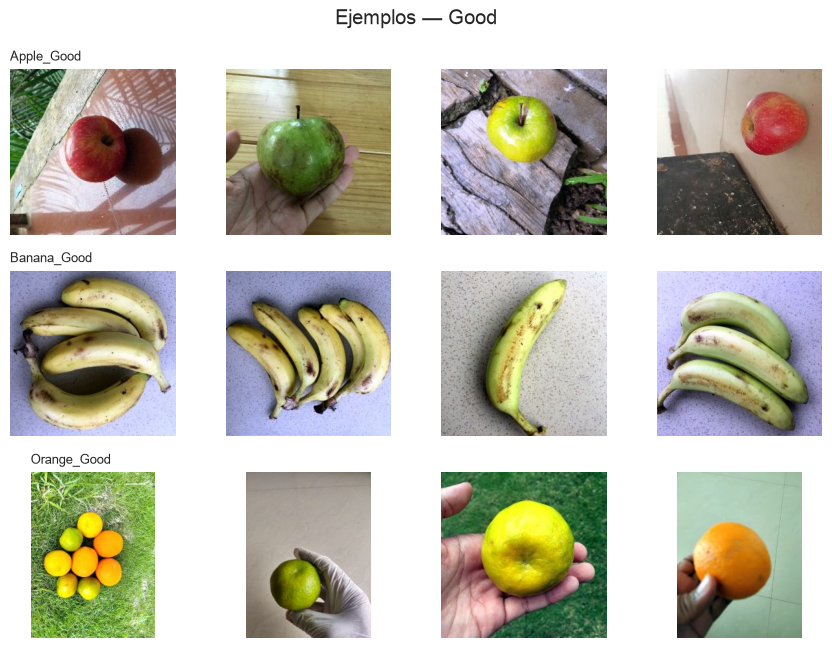

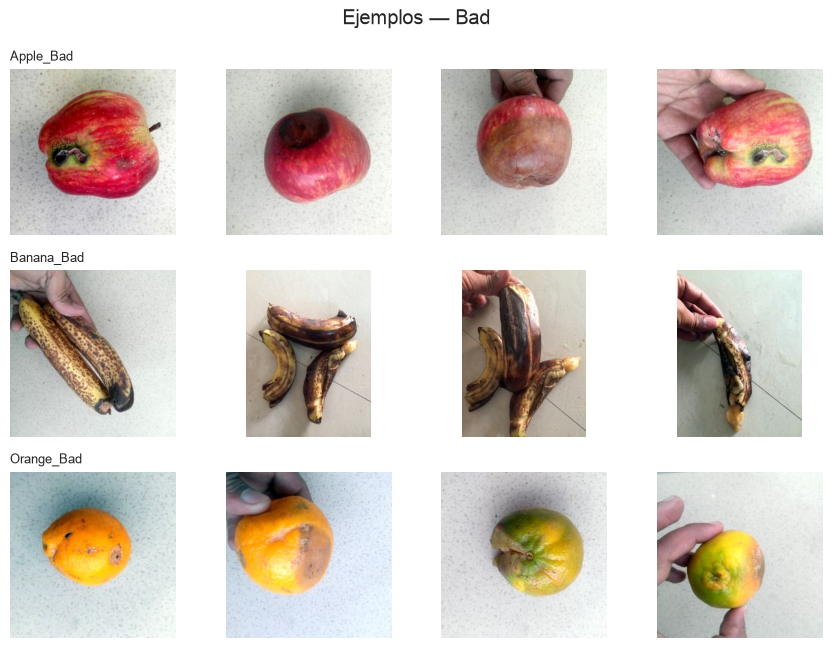

In [6]:
def show_grid(carpetas, titulo, fname, n_per=4):
    fig, axes = plt.subplots(len(carpetas), n_per, figsize=(n_per * 2.2, len(carpetas) * 2.2))
    for i, (grupo, carpeta) in enumerate(carpetas):
        files = list_images(RAW_DIR / grupo / carpeta)
        picks = random.sample(files, min(n_per, len(files)))
        for j in range(n_per):
            ax = axes[i, j] if len(carpetas) > 1 else axes[j]
            ax.axis("off")
            if j < len(picks):
                with Image.open(picks[j]) as im:
                    ax.imshow(im.convert("RGB"))
            if j == 0:
                ax.set_title(carpeta, fontsize=9, loc="left")
    fig.suptitle(titulo)
    plt.tight_layout()
    fig.savefig(ASSETS / fname, dpi=110)
    plt.show()

muestras_good = [("Good Quality_Fruits", c) for c in ["Apple_Good", "Banana_Good", "Orange_Good"]]
muestras_bad = [("Bad Quality_Fruits", c) for c in ["Apple_Bad", "Banana_Bad", "Orange_Bad"]]
show_grid(muestras_good, "Ejemplos — Good", "muestras_good.png")
show_grid(muestras_bad, "Ejemplos — Bad", "muestras_bad.png")

## 6. Análisis de color y brillo por clase

Comparamos el color/brillo promedio entre `Good` y `Bad` sobre una muestra: si hay diferencias,
el color será una característica útil para los modelos de ML tradicional.

Color/brillo promedio por calidad (muestra):
                  R           G           B      brillo
calidad                                                
Bad      172.800003  165.399994  152.600006  163.600006
Good     143.899994  142.500000  126.400002  137.600006


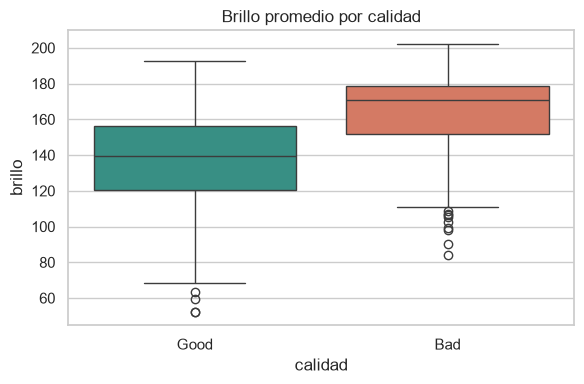

In [7]:
def color_stats(grupo, carpeta, n=80):
    files = list_images(RAW_DIR / grupo / carpeta)
    picks = random.sample(files, min(n, len(files)))
    means = []
    for f in picks:
        with Image.open(f) as im:
            arr = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32)
        means.append(arr.reshape(-1, 3).mean(axis=0))
    m = np.array(means)
    return pd.DataFrame(m, columns=["R", "G", "B"]).assign(
        brillo=m.mean(axis=1), calidad=("Good" if "Good" in carpeta else "Bad"), fruta=carpeta
    )

frutas = ["Apple", "Banana", "Orange", "Guava"]
dfc = pd.concat([
    color_stats(g, f"{fr}_{'Good' if g.startswith('Good') else 'Bad'}")
    for fr in frutas
    for g in ["Good Quality_Fruits", "Bad Quality_Fruits"]
], ignore_index=True)

resumen = dfc.groupby("calidad")[["R", "G", "B", "brillo"]].mean().round(1)
print("Color/brillo promedio por calidad (muestra):")
print(resumen)

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=dfc, x="calidad", y="brillo", hue="calidad", palette={"Good": "#2a9d8f", "Bad": "#e76f51"}, ax=ax, legend=False)
ax.set_title("Brillo promedio por calidad")
plt.tight_layout()
fig.savefig(ASSETS / "brillo_por_calidad.svg")
fig.savefig(ASSETS / "brillo_por_calidad.png", dpi=120)
plt.show()

## 7. Carpeta `Mixed Quality` (material para la clase `Defectuosa`)

Estas imágenes no traen etiqueta de calidad. Según la **opción A**, serán candidatas a anotarse
como la clase intermedia `Defectuosa` (junto con la recolección propia del equipo).

In [8]:
mixed = inv[inv["grupo"] == "Mixed Qualit_Fruits"][["carpeta", "n"]].rename(columns={"carpeta": "fruta"})
print(mixed.to_string(index=False))
print(f"\nTotal Mixed Quality: {mixed['n'].sum()}")

      fruta   n
      Apple 113
     Banana 285
      Guava 148
      Lemon 278
     Orange 125
Pomegranate 125

Total Mixed Quality: 1074


## 8. Hallazgos principales (resumen)

- **Volumen:** ~19.5k imágenes `.jpg`, 6 frutas (manzana, banano, guayaba, lima/limón, naranja, granada).
- **Solo 2 niveles de calidad etiquetados** (`Good`/`Bad`) → la 3.ª clase `Defectuosa` se construye
  por anotación propia + `Mixed Quality` (**opción A**).
- **Desbalanceo fuerte:** `Pomegranate_Good` domina (~5.9k) frente a ~1.1k del resto (ratio ≈ 5x).
  Además Good > Bad globalmente. → tratar con *class weights* / *augmentation* / submuestreo (Fase 3).
- **Dimensiones heterogéneas:** mayoría 256×256, pero hay imágenes de hasta miles de píxeles.
  → **redimensionado obligatorio** y normalización (Fase 3).
- **Color/brillo** muestra diferencias entre Good y Bad → característica prometedora para ML clásico.
- `Mixed Quality` (~1.1k) requiere **segmentación/anotación** manual.

Estos hallazgos alimentan la sección §2 de `docs/crisp-dm.md` y las decisiones de la Fase 3.